# Detecção de garimpo em imagens de satélite da Amazônia com DenseNet121

**Transfer learning e fine-tuning em Redes Neurais Convolucionais**

Machine Learning e Deep Learning · Profa. Polyana Santos Fonseca Nascimento · CESUPA · 2026/2

Classificamos recortes de imagens Sentinel-2 da Amazônia em `sem_garimpo` ou `com_garimpo` com uma DenseNet121 pré-treinada no ImageNet. Comparamos três condições: base congelada, fine-tuning A e fine-tuning B.

## 1. Apresentação

### • **Integrantes**

| Nome | Matrícula |
| --- | --- |
| Gabriel Costa de Miranda | 24070036 |
| João Pedro Silva da Silva | 24070017 |
| Yago Patrick Schnorr Pinto | 24070054 |

### • **Declaração de uso de IA generativa**

- **Ferramenta:** Claude Code (Anthropic), com o modelo Claude Opus 5.5.
- **Finalidade:** apoio na escrita do código e dos textos em Markdown.
- **Extensão:** cerca de 60% do notebook.
- **Validação:** cada etapa foi lida, executada e conferida pela equipe antes do commit, comparando as saídas com a lauda e os notebooks de aula. As análises foram escritas a partir das saídas reais.

### • **Contexto do problema**

Garimpos abertos na floresta deixam marcas visíveis do espaço: clareiras de solo exposto, cavas alagadas e rios com água barrenta. Essas marcas aparecem em imagens de satélite gratuitas, como as do Sentinel-2, que cobrem toda a Amazônia a cada poucos dias.

A área a vigiar, porém, é grande demais para inspeção visual de cada imagem. Um classificador automático pode fazer a primeira triagem e apontar onde vale a pena olhar com atenção.

### • **O que se classifica e finalidade**

Cada amostra é um recorte RGB de 128 × 128 pixels de um mosaico Sentinel-2. Com resolução de 10 m, o recorte cobre cerca de 1,28 km × 1,28 km. O modelo responde a uma pergunta binária: o recorte está em uma área de garimpo (`com_garimpo`) ou não (`sem_garimpo`)?

Uma finalidade possível é a **triagem para fiscalização**: aplicar o modelo a grandes áreas e priorizar, para análise de especialistas ou de órgãos ambientais, os recortes com maior probabilidade de garimpo. Nesse uso, o erro mais grave é o falso negativo, um garimpo que passa sem ser detectado.

### • **Dataset e justificativa da escolha**

Usamos o [Dataset Amazonia Garimpo Binario](https://www.kaggle.com/datasets/leogrupioni/dataset-amazonia-garimpo-binario), publicado no Kaggle por Leonardo Grupioni. A construção do dataset é descrita no artigo de Grupioni, Almeida, Gallois e Ranzini, *Detecção de Garimpo na Amazônia com Visão Computacional e Redes Neurais Convolucionais*, Revista Eletrônica de Iniciação Científica em Computação, 2026, [doi:10.5753/reic.2026.7570](https://doi.org/10.5753/reic.2026.7570).

Justificativa da escolha:

- **Relevância:** trata de um problema ambiental real da Amazônia, com uso prático em monitoramento.
- **Origem confiável e rastreável:** as imagens vêm do Sentinel-2 (nível 2A, com máscara de nuvens) e os rótulos vêm dos polígonos de garimpo da RAISG. Um arquivo de manifesto liga cada recorte às suas coordenadas e à fração de sobreposição com os polígonos.
- **Tamanho e equilíbrio:** cerca de 111 mil imagens, com as duas classes em proporções próximas. Isso atende com folga ao mínimo de 1.000 imagens e 100 por classe e permite trabalhar com uma amostra.
- **Pouco explorado:** é um dataset recente, de 2026, não trabalhado em sala.

Trabalhamos com uma amostra estratificada de 20.000 imagens para manter o tempo de treino viável nas três condições.

## 2. Arquitetura: DenseNet121

#### Identificação

| | |
| --- | --- |
| **Versão** | DenseNet121 |
| **Autores e ano** | Gao Huang, Zhuang Liu, Laurens van der Maaten e Kilian Q. Weinberger, 2017 |
| **Artigo** | *Densely Connected Convolutional Networks*, CVPR 2017. [arXiv:1608.06993](https://arxiv.org/abs/1608.06993) |

#### Diagrama

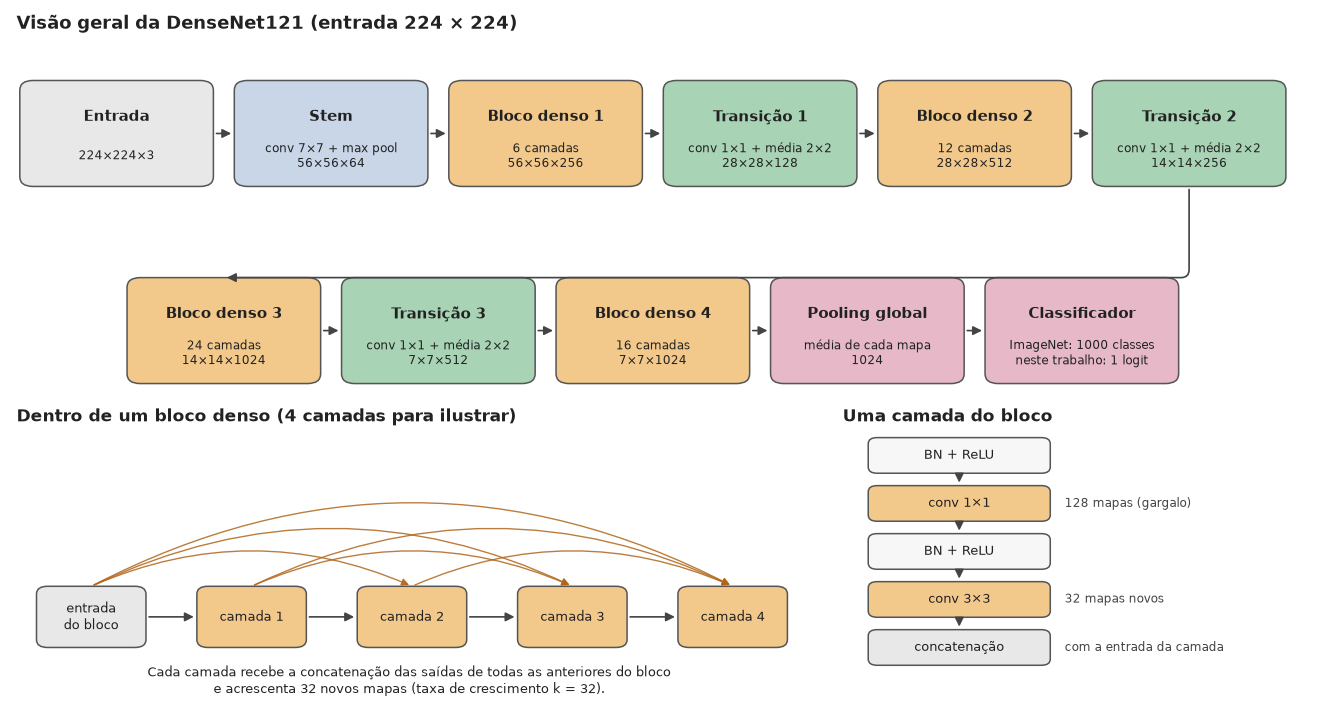

- **Stem:** reduz a imagem de 224 para 56 pixels de lado.
- **Blocos densos:** cada camada acrescenta 32 mapas, sem mudar o tamanho da imagem.
- **Transições:** reduzem pela metade o número de mapas e o lado da imagem.
- **Final:** pooling global e classificador. Neste trabalho, as 1000 classes do ImageNet viram um único logit.

#### Principal inovação: conexões densas

Numa CNN convencional, cada camada recebe só a saída da anterior. Na DenseNet, cada camada recebe as saídas de **todas** as camadas anteriores do bloco, por concatenação. Assim as características já aprendidas são reaproveitadas, as camadas podem ser estreitas e o gradiente chega com mais facilidade às primeiras camadas. A ResNet soma as saídas; a DenseNet concatena.

#### Diferencial da versão 121

121 é o número de camadas com pesos: 1 no stem, 116 nos blocos, 3 nas transições e 1 no classificador.

| Versão | Camadas por bloco | Parâmetros |
| --- | --- | --- |
| **DenseNet121** | 6, 12, 24, 16 | 8,1 milhões |
| DenseNet169 | 6, 12, 32, 32 | 14,3 milhões |
| DenseNet201 | 6, 12, 48, 32 | 20,2 milhões |

A 121 é a menor da família, o que torna viável treinar as três condições no Colab.

## 3. Dados

#### Bibliotecas e configuração

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import hashlib
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow import keras
import kagglehub

SEMENTE = 42
SEMENTES = [42, 43, 44, 45, 46]
TAMANHO = (224, 224)
BATCH_SIZE = 32
EPOCAS = 30
PACIENCIA = 5
MODO_RAPIDO = False
if MODO_RAPIDO:
    SEMENTES = SEMENTES[:2]
NOMES_CLASSES = ["sem_garimpo", "com_garimpo"]
keras.utils.set_random_seed(SEMENTE)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.15.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#### Download dos dados pelo kagglehub

In [2]:
PASTA_DADOS = Path(kagglehub.dataset_download("leogrupioni/dataset-amazonia-garimpo-binario", output_dir="dados/kaggle"))
PASTA_IMAGENS = PASTA_DADOS / "dataset_amazonia_garimpo_binario"
print(sorted(p.name for p in PASTA_IMAGENS.iterdir()))

['com_garimpo', 'manifesto_chips.csv', 'sem_garimpo']


#### Inspeção dos arquivos

In [3]:
caminhos = [p for p in PASTA_IMAGENS.rglob("*") if p.is_file()]
arquivos = pd.DataFrame({
    "pasta": [p.parent.name for p in caminhos],
    "extensao": [p.suffix for p in caminhos]})
pd.crosstab(arquivos.pasta, arquivos.extensao, margins=True, margins_name="total")

extensao,.csv,.png,total
pasta,,,
com_garimpo,0,55541,55541
dataset_amazonia_garimpo_binario,1,0,1
sem_garimpo,0,56043,56043
total,1,111584,111585


#### Entendendo o manifesto.csv

In [4]:
manifesto = pd.read_csv(PASTA_IMAGENS / "manifesto_chips.csv")
print(manifesto.shape)
manifesto.label_str.value_counts()

(111584, 27)


label_str
sem_garimpo    56043
com_garimpo    55541
Name: count, dtype: int64

In [5]:
# Colunas que descrevem a origem dos recortes: têm um único valor em todo o dataset.
manifesto[["tile_size_px", "bands_used", "dtype_src", "utm_epsg"]].drop_duplicates()

,tile_size_px,bands_used,dtype_src,utm_epsg
0,128,"['B4', 'B3', 'B2']",float32,32721


In [6]:
# Os recortes vêm de 12 arquivos .tif vizinhos do mesmo mosaico.
manifesto.groupby("tif_source").label_int.agg(recortes="size", fracao_com_garimpo="mean").round(3)

,recortes,fracao_com_garimpo
tif_source,,
v3_new_ret_s2_median_2024_dry-0000000000-0000000000.tif,11236,0.465
v3_new_ret_s2_median_2024_dry-0000000000-0000013568.tif,11236,0.597
v3_new_ret_s2_median_2024_dry-0000000000-0000027136.tif,11130,0.235
v3_new_ret_s2_median_2024_dry-0000013568-0000000000.tif,11236,0.578
v3_new_ret_s2_median_2024_dry-0000013568-0000013568.tif,11236,0.892
v3_new_ret_s2_median_2024_dry-0000013568-0000027136.tif,11130,0.550
v3_new_ret_s2_median_2024_dry-0000027136-0000000000.tif,11236,0.060
v3_new_ret_s2_median_2024_dry-0000027136-0000013568.tif,11236,0.567
v3_new_ret_s2_median_2024_dry-0000027136-0000027136.tif,11130,0.820


#### Formato das imagens

In [7]:
exemplos = manifesto.groupby("label_str").sample(5, random_state=SEMENTE)
for exemplo in exemplos.itertuples():
    conteudo = tf.io.read_file(str(PASTA_IMAGENS / exemplo.png_path))
    imagem = tf.io.decode_png(conteudo).numpy()
    print(f"{exemplo.label_str}: formato {imagem.shape}, tipo {imagem.dtype}, "
          f"mín {imagem.min()}, máx {imagem.max()}, média {imagem.mean():.1f}")

com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 194, média 7.9
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 97, média 5.2
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 34, média 4.8
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 218, média 13.8
com_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 45, média 8.1
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 63, média 9.0
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 102, média 6.6
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 44, média 7.0
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 37, média 6.8
sem_garimpo: formato (128, 128, 3), tipo uint8, mín 0, máx 40, média 7.1


#### Origem dos rótulos
O rótulo vem da sobreposição de cada recorte com polígonos de garimpo da RAISG (`overlap_ratio`).

In [8]:
manifesto.groupby("label_str")['overlap_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
label_str,,,,,,,,
com_garimpo,55541.0,1.003981,0.274265,0.050329,0.999998,1.0,1.0,3.310692
sem_garimpo,56043.0,0.000227,0.002678,0.000000,0.000000,0.0,0.0,0.049813


#### **Resumo da inspeção**

- **Formato:** PNG RGB de 8 bits, 128 × 128 pixels, bandas B4, B3 e B2 do Sentinel-2. Não é preciso converter.
- **Classes:** 56.043 `sem_garimpo` e 55.541 `com_garimpo` (50,2% e 49,8%). Não usaremos `class_weight`.
- **Brilho:** as imagens são escuras (média perto de 8 em 255). Tratamos isso no pré-processamento.
- **Rótulo:** `com_garimpo` quando mais de 5% do recorte cai em um polígono da RAISG. Os polígonos marcam áreas de garimpo, não só o solo exposto; um recorte positivo pode ser quase todo floresta. Verificamos isso visualmente na análise exploratória.
- **Região:** 12 blocos vizinhos, com fração de garimpo de 0% a 89%. As coordenadas permitem dividir os dados por região.

#### Blocos espaciais
Recortes vizinhos mostram a mesma paisagem. Se caírem em divisões diferentes, a validação e o teste ficam otimistas. Por isso agrupamos os recortes em blocos de 8 × 8 (cerca de 10 km de lado), e cada bloco vai inteiro para uma única divisão.

In [9]:
TAMANHO_BLOCO = 8

partes_nome = manifesto.tif_source.str.replace(".tif", "").str.split("-")
linha_tif = partes_nome.str[1].astype(int) // 128
coluna_tif = partes_nome.str[2].astype(int) // 128

tabela = pd.DataFrame({
    "arquivo": manifesto.png_path,
    "rotulo": manifesto.label_int,
    "classe": manifesto.label_str,
    "linha": linha_tif + manifesto.tile_row,
    "coluna": coluna_tif + manifesto.tile_col,
    "overlap_ratio": manifesto.overlap_ratio})

linha_bloco = tabela.linha // TAMANHO_BLOCO
coluna_bloco = tabela.coluna // TAMANHO_BLOCO
tabela["bloco"] = linha_bloco.astype(str) + "_" + coluna_bloco.astype(str)
print("Blocos:", tabela.bloco.nunique())

Blocos: 1760


#### Amostra e divisão
Primeiro repartimos os blocos de todo o dataset em 20 partes com `StratifiedGroupKFold`: 3 para teste, 3 para validação e 14 para treino. Depois sorteamos 14.000, 3.000 e 3.000 imagens, com a mesma proporção de classes em cada divisão.

Fazemos isso com 5 sementes (42 a 46), uma divisão por semente, para que os resultados não dependam de quais imagens caíram em cada conjunto. As divisões ficam em `dados/divisoes/`, e nas execuções seguintes o notebook lê esses arquivos em vez de sortear de novo. A análise exploratória usa o treino da semente 42.

In [10]:
PASTA_DIVISOES = Path("dados/divisoes")
PASTA_DIVISOES.mkdir(exist_ok=True)
TAMANHOS = {"treino": 14000, "validacao": 3000, "teste": 3000}

def dividir(semente):
    tabela_semente = tabela.copy()

    # 1. Reparte os blocos em 20 partes com proporções de classe parecidas
    divisor = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=semente)
    tabela_semente["parte"] = 0
    numero = 0
    for indices_fora, indices_da_parte in divisor.split(tabela_semente, tabela_semente.rotulo, groups=tabela_semente.bloco):
        tabela_semente.loc[indices_da_parte, "parte"] = numero
        numero += 1

    # 2. Partes 0 a 2 viram teste, 3 a 5 validação e as demais treino
    tabela_semente["divisao"] = "treino"
    tabela_semente.loc[tabela_semente.parte < 6, "divisao"] = "validacao"
    tabela_semente.loc[tabela_semente.parte < 3, "divisao"] = "teste"

    # 3. Em cada divisão, sorteia o número exato de imagens de cada classe
    proporcao_com = tabela_semente.rotulo.mean()
    sorteios = []
    for divisao, n_imagens in TAMANHOS.items():
        n_com = round(n_imagens * proporcao_com)
        n_sem = n_imagens - n_com
        candidatas = tabela_semente[tabela_semente.divisao == divisao]
        sorteios.append(candidatas[candidatas.rotulo == 0].sample(n_sem, random_state=semente))
        sorteios.append(candidatas[candidatas.rotulo == 1].sample(n_com, random_state=semente))
    return pd.concat(sorteios, ignore_index=True).drop(columns="parte")

divisoes = {}
for semente in SEMENTES:
    caminho = PASTA_DIVISOES / f"divisao_semente_{semente}.csv"
    if caminho.exists():
        divisoes[semente] = pd.read_csv(caminho)
    else:
        divisoes[semente] = dividir(semente)
        divisoes[semente].to_csv(caminho, index=False)

amostra = divisoes[SEMENTE]

resumo_divisoes = []
for semente, amostra_semente in divisoes.items():
    divisoes_por_bloco = amostra_semente.groupby("bloco").divisao.nunique()
    resumo_divisoes.append({"semente": semente,
                            "treino": (amostra_semente.divisao == "treino").sum(),
                            "validacao": (amostra_semente.divisao == "validacao").sum(),
                            "teste": (amostra_semente.divisao == "teste").sum(),
                            "% com_garimpo": round(100 * amostra_semente.rotulo.mean(), 1),
                            "blocos em mais de uma divisão": (divisoes_por_bloco > 1).sum()})
pd.DataFrame(resumo_divisoes)

,semente,treino,validacao,teste,% com_garimpo,blocos em mais de uma divisão
0,42,14000,3000,3000,49.8,0
1,43,14000,3000,3000,49.8,0
2,44,14000,3000,3000,49.8,0
3,45,14000,3000,3000,49.8,0
4,46,14000,3000,3000,49.8,0


#### Visualizando como ficou a divisão entre **treino**, **teste** e **validação**

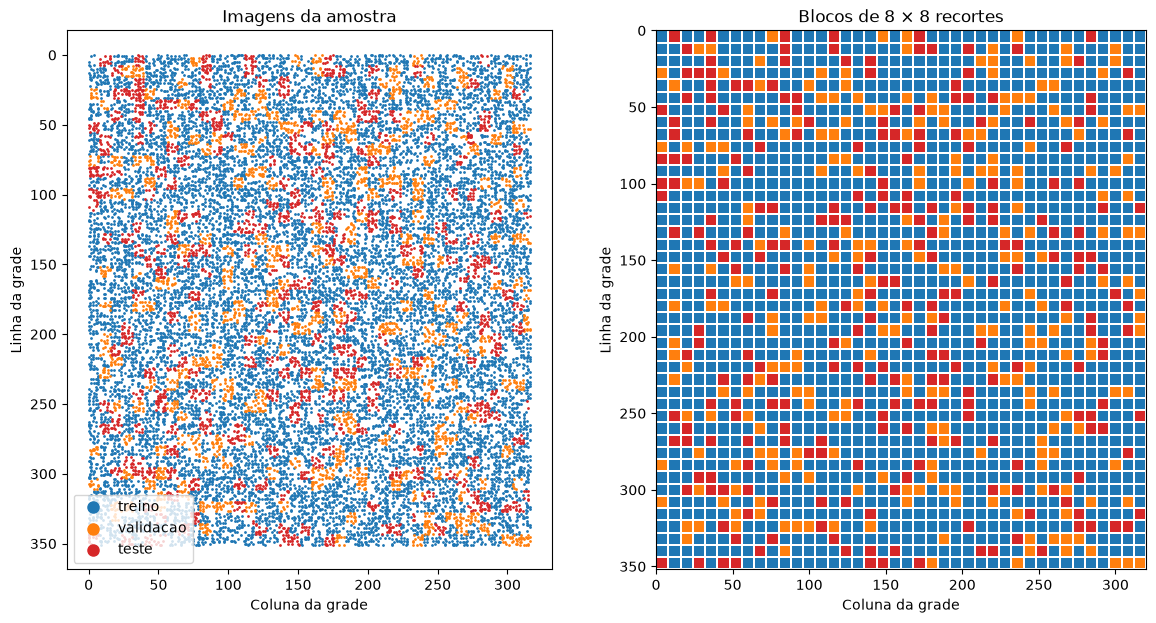

In [11]:
DIVISOES = ["treino", "validacao", "teste"]
CORES = ["tab:blue", "tab:orange", "tab:red"]

n_linhas_blocos = amostra.linha.max() // TAMANHO_BLOCO + 1
n_colunas_blocos = amostra.coluna.max() // TAMANHO_BLOCO + 1
matriz = np.full((n_linhas_blocos, n_colunas_blocos), np.nan)
for imagem in amostra.itertuples():
    matriz[imagem.linha // TAMANHO_BLOCO, imagem.coluna // TAMANHO_BLOCO] = DIVISOES.index(imagem.divisao)

fig, eixos = plt.subplots(1, 2, figsize=(14, 7))

for divisao, cor in zip(DIVISOES, CORES):
    parte = amostra[amostra.divisao == divisao]
    eixos[0].scatter(parte.coluna, parte.linha, s=1, color=cor, label=divisao)
eixos[0].legend(markerscale=8, loc="lower left")
eixos[0].set_title("Imagens da amostra")

bordas_x = np.arange(n_colunas_blocos + 1) * TAMANHO_BLOCO
bordas_y = np.arange(n_linhas_blocos + 1) * TAMANHO_BLOCO
eixos[1].pcolormesh(bordas_x, bordas_y, matriz, cmap=ListedColormap(CORES), edgecolors="white", linewidth=0.3)
eixos[1].set_title(f"Blocos de {TAMANHO_BLOCO} × {TAMANHO_BLOCO} recortes")

for eixo in eixos:
    eixo.set(xlabel="Coluna da grade", ylabel="Linha da grade", aspect="equal")
    eixo.invert_yaxis()
plt.show()

#### Análise exploratória

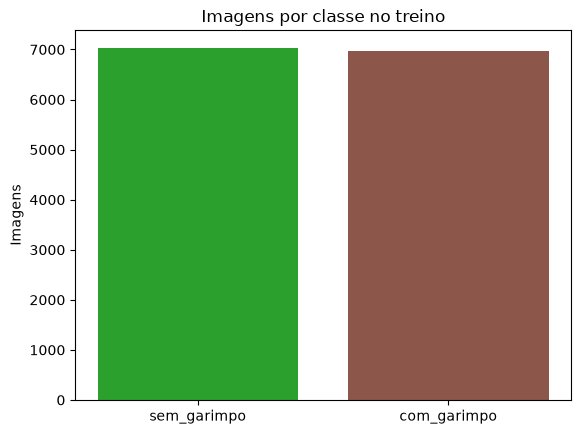

In [12]:
treino = amostra[amostra.divisao == "treino"].reset_index(drop=True)

contagem = treino.classe.value_counts()
plt.bar(contagem.index, contagem.values, color=["tab:green", "tab:brown"])
plt.title("Imagens por classe no treino")
plt.ylabel("Imagens")
plt.show()

#### Exemplos de cada classe

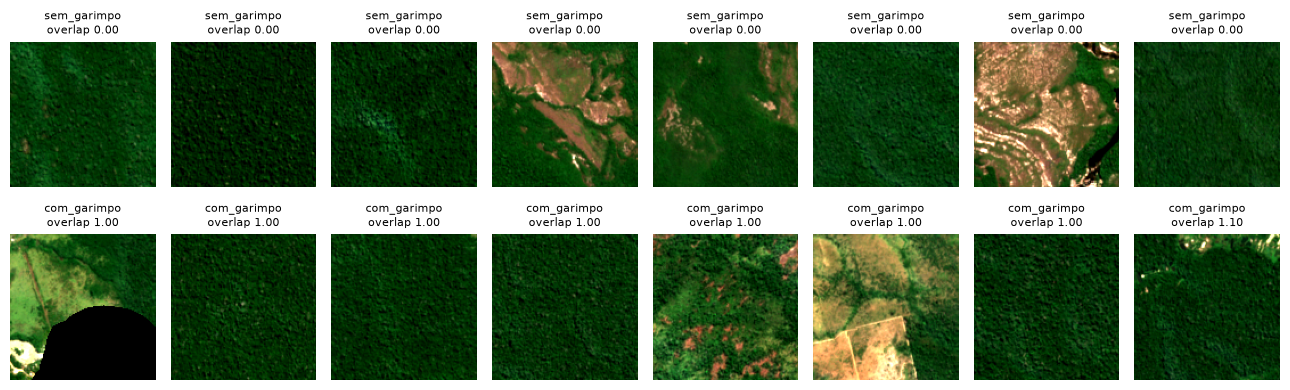

In [13]:
AUMENTO_BRILHO = 3

def ler_imagem(arquivo):
    conteudo = tf.io.read_file(str(PASTA_IMAGENS / arquivo))
    return tf.io.decode_png(conteudo, channels=3).numpy()

fig, eixos = plt.subplots(2, 8, figsize=(13, 4.2))
for linha_eixos, classe in zip(eixos, NOMES_CLASSES):
    exemplos = treino[treino.classe == classe].sample(8, random_state=SEMENTE)
    for eixo, exemplo in zip(linha_eixos, exemplos.itertuples()):
        imagem = ler_imagem(exemplo.arquivo).astype("float32") * AUMENTO_BRILHO
        eixo.imshow(np.clip(imagem, 0, 255).astype("uint8"))
        eixo.set_title(f"{classe}\noverlap {exemplo.overlap_ratio:.2f}", fontsize=8)
        eixo.axis("off")
plt.tight_layout()
plt.show()

#### Cor e brilho por classe

In [14]:
medias = []
for arquivo in treino.arquivo:
    imagem = ler_imagem(arquivo)
    medias.append(imagem.mean(axis=(0, 1)))

cores = pd.DataFrame(medias, columns=["R", "G", "B"])
cores["classe"] = treino.classe
cores.groupby("classe").agg(["mean", "std"]).round(1)

R           G          B     
             mean   std  mean   std mean  std
classe                                       
com_garimpo  12.5  20.6  23.5  12.2  7.1  8.8
sem_garimpo   3.6   6.5  18.7   4.9  3.4  3.5

Aqui da para notar uma diferença entre as médias de cor por classe, a média da cores na classe "com_garimpo" é maior do que na classe "sem_garimpo". Entretanto o desvio padrão muda muito, isso provavelmente se deve a áreas que estão classificadas como "com_garimpo" mas são áreas de preservação daquele garimpo (no caso de garimpos legais).

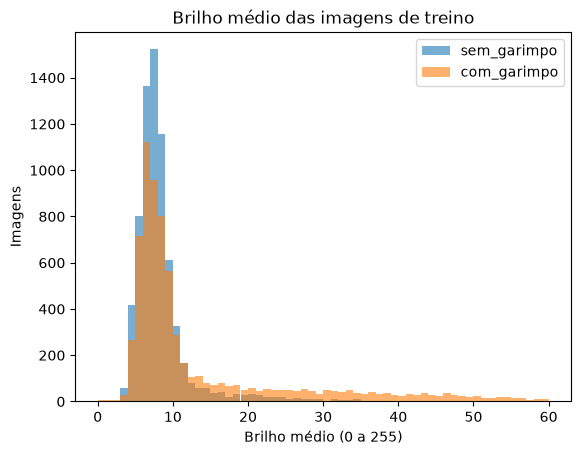

In [15]:
cores["brilho"] = cores[["R", "G", "B"]].mean(axis=1)

for classe in NOMES_CLASSES:
    plt.hist(cores.brilho[cores.classe == classe], bins=60, range=(0, 60), alpha=0.6, label=classe)
plt.title("Brilho médio das imagens de treino")
plt.xlabel("Brilho médio (0 a 255)")
plt.ylabel("Imagens")
plt.legend()
plt.show()

#### Brilho por faixa de overlap

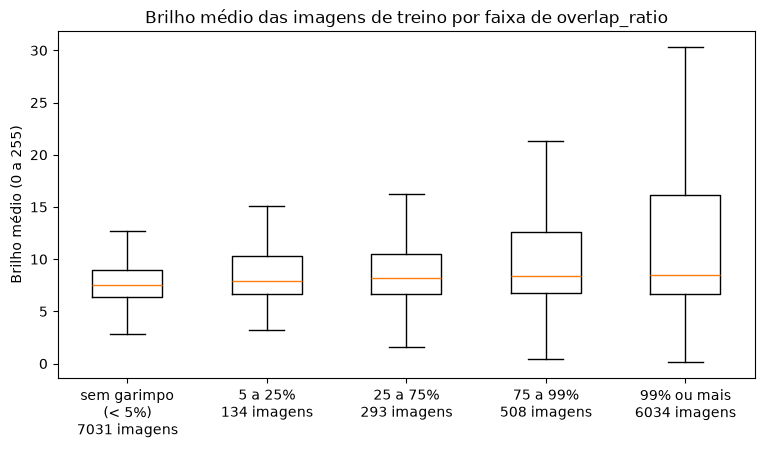

In [16]:
def faixa_overlap(overlap):
    if overlap < 0.05:
        return "sem garimpo\n(< 5%)"
    if overlap < 0.25:
        return "5 a 25%"
    if overlap < 0.75:
        return "25 a 75%"
    if overlap < 0.99:
        return "75 a 99%"
    return "99% ou mais"

cores["faixa"] = treino.overlap_ratio.map(faixa_overlap)
FAIXAS = ["sem garimpo\n(< 5%)", "5 a 25%", "25 a 75%", "75 a 99%", "99% ou mais"]

brilho_por_faixa = [cores.brilho[cores.faixa == faixa] for faixa in FAIXAS]
nomes_eixo = [f"{faixa}\n{len(brilhos)} imagens" for faixa, brilhos in zip(FAIXAS, brilho_por_faixa)]

plt.figure(figsize=(9, 4.5))
plt.boxplot(brilho_por_faixa, tick_labels=nomes_eixo, showfliers=False)
plt.title("Brilho médio das imagens de treino por faixa de overlap_ratio")
plt.ylabel("Brilho médio (0 a 255)")
plt.show()

#### Onde está o garimpo

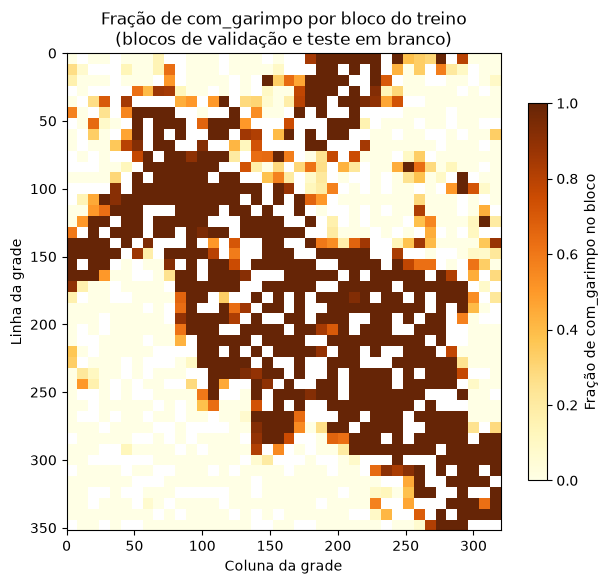

In [17]:
fracao_por_bloco = treino.groupby("bloco").rotulo.mean()

matriz_fracao = np.full((n_linhas_blocos, n_colunas_blocos), np.nan)
for bloco, fracao in fracao_por_bloco.items():
    linha_bloco, coluna_bloco = bloco.split("_")
    matriz_fracao[int(linha_bloco), int(coluna_bloco)] = fracao

plt.figure(figsize=(7, 7))
plt.pcolormesh(bordas_x, bordas_y, matriz_fracao, cmap="YlOrBr", vmin=0, vmax=1)
plt.colorbar(label="Fração de com_garimpo no bloco", shrink=0.7)
plt.title("Fração de com_garimpo por bloco do treino\n(blocos de validação e teste em branco)")
plt.xlabel("Coluna da grade")
plt.ylabel("Linha da grade")
plt.gca().set_aspect("equal")
plt.gca().invert_yaxis()
plt.show()

#### Áreas mascaradas (pixels pretos)

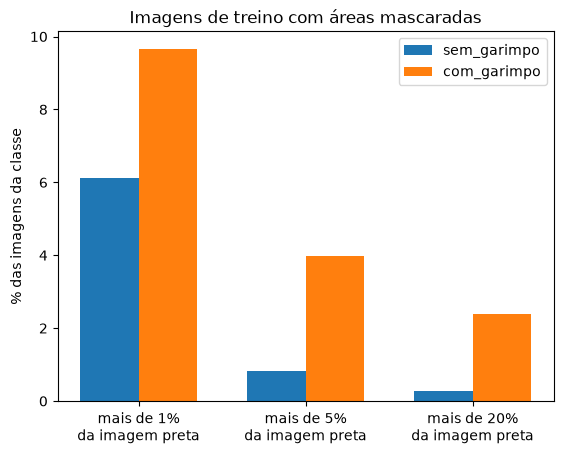

In [18]:
fracao_preta = []
for arquivo in treino.arquivo:
    imagem = ler_imagem(arquivo)
    pixels_pretos = imagem.sum(axis=2) == 0
    fracao_preta.append(pixels_pretos.mean())
cores["fracao_preta"] = fracao_preta

LIMITES = [0.01, 0.05, 0.20]
largura = 0.35
posicoes = np.arange(len(LIMITES))
for deslocamento, classe in zip([-largura / 2, largura / 2], NOMES_CLASSES):
    imagens_classe = cores[cores.classe == classe]
    percentuais = [100 * (imagens_classe.fracao_preta > limite).mean() for limite in LIMITES]
    plt.bar(posicoes + deslocamento, percentuais, largura, label=classe)

plt.xticks(posicoes, [f"mais de {limite:.0%}\nda imagem preta" for limite in LIMITES])
plt.title("Imagens de treino com áreas mascaradas")
plt.ylabel("% das imagens da classe")
plt.legend()
plt.show()

## 4. EDA orientada a hipóteses

#### H1. A maioria dos positivos não mostra garimpo visível

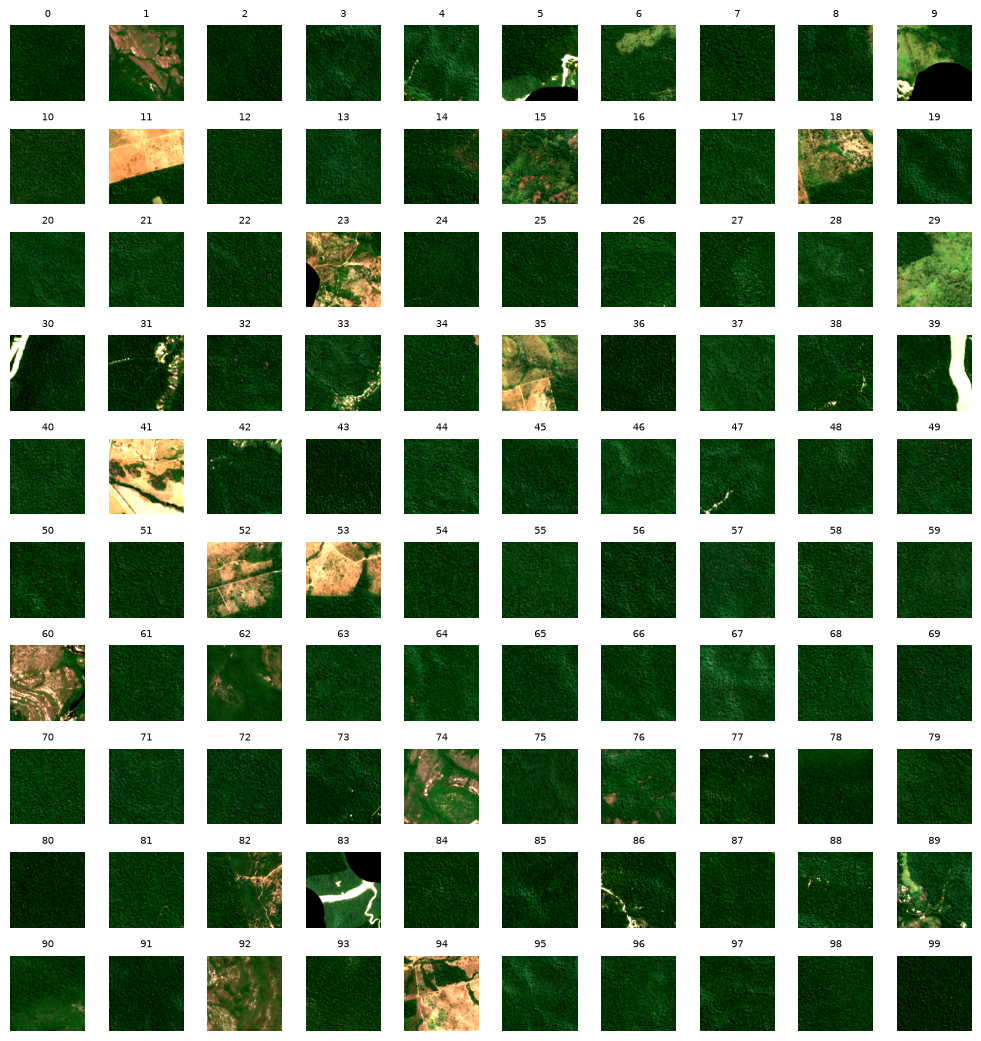

In [19]:
amostra_com = treino[treino.rotulo == 1].sample(50, random_state=SEMENTE)
amostra_sem = treino[treino.rotulo == 0].sample(50, random_state=SEMENTE)
auditoria = pd.concat([amostra_com, amostra_sem]).sample(frac=1, random_state=SEMENTE).reset_index(drop=True)

fig, eixos = plt.subplots(10, 10, figsize=(10, 10.5))
eixos = eixos.ravel()
for numero in range(len(auditoria)):
    imagem = ler_imagem(auditoria.arquivo[numero]).astype("float32") * AUMENTO_BRILHO
    eixos[numero].imshow(np.clip(imagem, 0, 255).astype("uint8"))
    eixos[numero].set_title(str(numero), fontsize=7)
    eixos[numero].axis("off")
plt.tight_layout()
plt.show()

In [20]:
# Números das imagens em que a equipe viu garimpo, anotados sem saber a classe
numeros_com_garimpo_visivel = [1, 5, 9, 11, 15, 18, 23, 29, 31, 33, 35, 41, 47, 52, 53, 60, 62, 74, 76, 82, 86, 89, 90, 92, 94]

auditoria["garimpo_visivel"] = auditoria.index.isin(numeros_com_garimpo_visivel)
pd.crosstab(auditoria.classe, auditoria.garimpo_visivel)

garimpo_visivel,False,True
classe,,
com_garimpo,34,16
sem_garimpo,41,9


**Análise:** a equipe viu garimpo em só 16 das 50 imagens `com_garimpo` (32%), o que confirma a hipótese: na maioria dos positivos o rótulo não tem marca visível na imagem. Também apontamos garimpo em 9 das 50 negativas (18%), provavelmente outros tipos de solo exposto. Com 100 imagens a estimativa é grosseira, mas mostra que boa parte dos rótulos não pode ser aprendida pela aparência, o que deve limitar o desempenho de qualquer modelo.

#### H2. Negativos com solo exposto ficam perto das frentes de garimpo

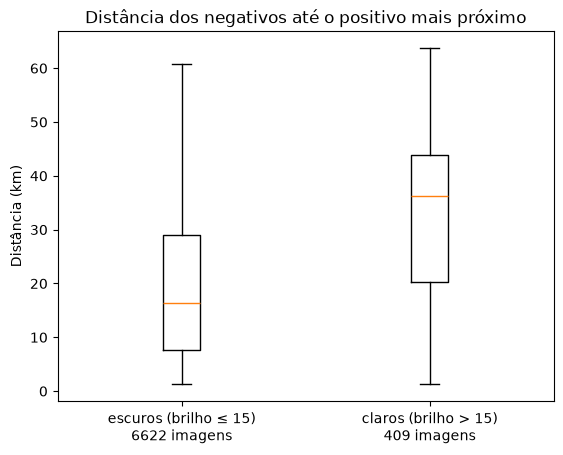

In [21]:
positivos = treino[treino.rotulo == 1]
negativos = treino[treino.rotulo == 0]

busca = NearestNeighbors(n_neighbors=1).fit(positivos[["linha", "coluna"]])
distancias, indices = busca.kneighbors(negativos[["linha", "coluna"]])
distancia_km = distancias[:, 0] * 1.28 

claros = (cores.brilho[negativos.index] > 15).to_numpy()
plt.boxplot([distancia_km[~claros], distancia_km[claros]],
            tick_labels=[f"escuros (brilho ≤ 15)\n{(~claros).sum()} imagens", f"claros (brilho > 15)\n{claros.sum()} imagens"],
            showfliers=False)
plt.title("Distância dos negativos até o positivo mais próximo")
plt.ylabel("Distância (km)")
plt.show()

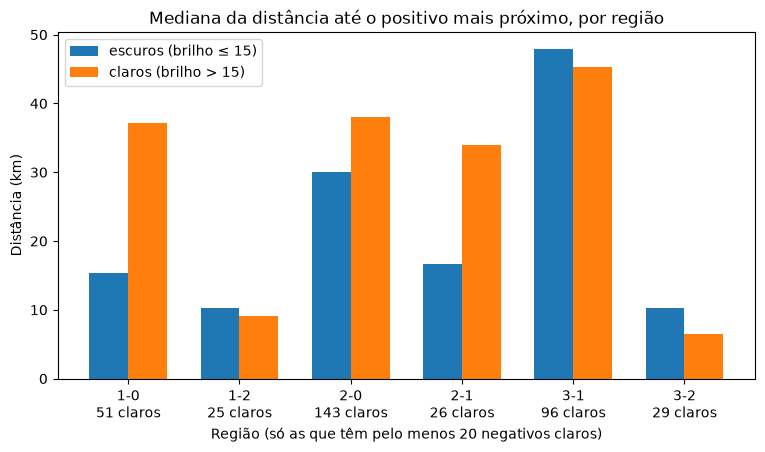

In [22]:
regiao = (treino.linha // 106).astype(str) + "-" + (treino.coluna // 106).astype(str)

regiao_negativos = regiao[negativos.index].to_numpy()
medianas_escuros = pd.Series(distancia_km[~claros]).groupby(regiao_negativos[~claros]).median()
medianas_claros = pd.Series(distancia_km[claros]).groupby(regiao_negativos[claros]).median()
quantidade_claros = pd.Series(claros).groupby(regiao_negativos).sum()
regioes_comparaveis = quantidade_claros[quantidade_claros >= 20].index

largura = 0.35
posicoes = np.arange(len(regioes_comparaveis))
plt.figure(figsize=(9, 4.5))
plt.bar(posicoes - largura / 2, medianas_escuros[regioes_comparaveis], largura, label="escuros (brilho ≤ 15)")
plt.bar(posicoes + largura / 2, medianas_claros[regioes_comparaveis], largura, label="claros (brilho > 15)")
plt.xticks(posicoes, [f"{r}\n{quantidade_claros[r]} claros" for r in regioes_comparaveis])
plt.title("Mediana da distância até o positivo mais próximo, por região")
plt.xlabel("Região (só as que têm pelo menos 20 negativos claros)")
plt.ylabel("Distância (km)")
plt.legend()
plt.show()

**Análise:** a hipótese não se confirma. No total, os negativos claros parecem mais longe do garimpo (mediana de 36 km contra 16 km), mas isso vem de onde eles estão: mais da metade fica nas regiões 2-0 e 3-1, que já são distantes das frentes. Comparando dentro de cada região, a diferença muda de sentido: os claros ficam mais longe em 1-0, 2-0 e 2-1, e na mesma distância ou mais perto em 1-2, 3-1 e 3-2. Ou seja, o brilho de um negativo não indica se ele está perto do garimpo, e nada sugere garimpo fora do mapeamento entre eles. Esses negativos claros devem ser outro uso do solo, como pasto ou desmatamento, e são candidatos a falso positivo se a CNN associar solo claro a garimpo.

#### H3. O brilho muda de uma região para outra mesmo sem garimpo

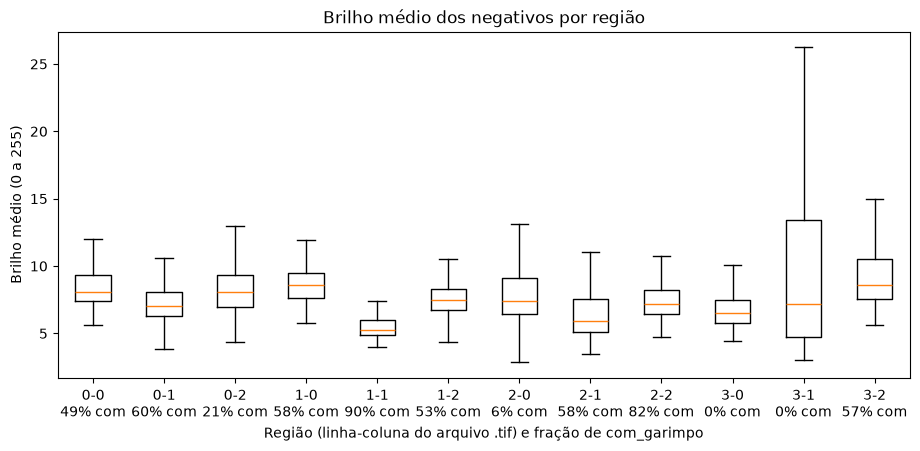

In [23]:
REGIOES = sorted(regiao.unique())
fracao_por_regiao = treino.rotulo.groupby(regiao).mean()

brilho_negativos = [cores.brilho[(regiao == r) & (treino.rotulo == 0)] for r in REGIOES]
nomes_eixo = [f"{r}\n{fracao_por_regiao[r]:.0%} com" for r in REGIOES]

plt.figure(figsize=(11, 4.5))
plt.boxplot(brilho_negativos, tick_labels=nomes_eixo, showfliers=False)
plt.title("Brilho médio dos negativos por região")
plt.xlabel("Região (linha-coluna do arquivo .tif) e fração de com_garimpo")
plt.ylabel("Brilho médio (0 a 255)")
plt.show()

**Análise:** a mediana do brilho dos negativos vai de cerca de 5 a 9 entre as regiões, então a hipótese se confirma em parte. Essa variação, porém, não acompanha a fração de garimpo: a região 1-1 (90% com) tem os negativos mais escuros, e as regiões sem nenhum positivo (3-0 e 3-1) ficam no meio. A região 3-1 tem uma dispersão bem maior que as outras. O risco de o modelo usar o brilho da região como atalho parece baixo.

#### H4. As áreas mascaradas se concentram em poucas regiões

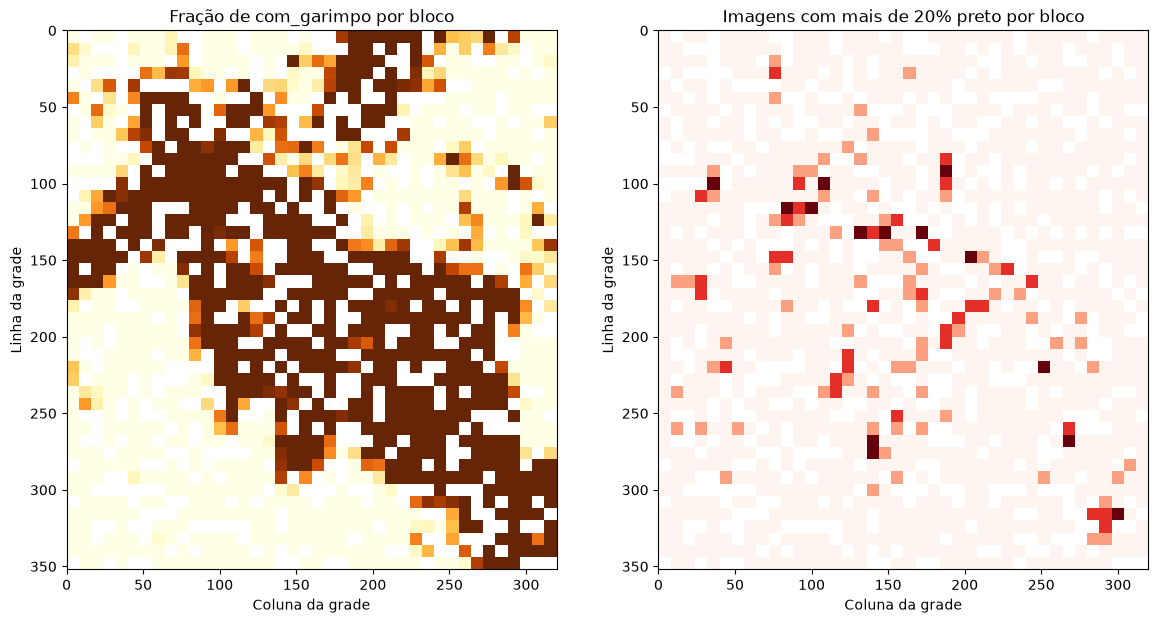

In [24]:
mascarada = cores.fracao_preta > 0.20
mascaradas_por_bloco = mascarada.groupby(treino.bloco).sum()

matriz_mascaras = np.full((n_linhas_blocos, n_colunas_blocos), np.nan)
for bloco, quantidade in mascaradas_por_bloco.items():
    linha_bloco, coluna_bloco = bloco.split("_")
    matriz_mascaras[int(linha_bloco), int(coluna_bloco)] = quantidade

fig, eixos = plt.subplots(1, 2, figsize=(14, 7))
eixos[0].pcolormesh(bordas_x, bordas_y, matriz_fracao, cmap="YlOrBr", vmin=0, vmax=1)
eixos[0].set_title("Fração de com_garimpo por bloco")
eixos[1].pcolormesh(bordas_x, bordas_y, matriz_mascaras, cmap="Reds", vmin=0, vmax=3)
eixos[1].set_title("Imagens com mais de 20% preto por bloco")
for eixo in eixos:
    eixo.set(xlabel="Coluna da grade", ylabel="Linha da grade", aspect="equal")
    eixo.invert_yaxis()
plt.show()

In [25]:
percentual_mascaradas = 100 * mascarada.groupby([regiao, treino.classe]).mean()
percentual_mascaradas.unstack().round(1)

classe,com_garimpo,sem_garimpo
0-0,1.9,0.1
0-1,1.6,1.3
0-2,0.0,0.0
1-0,2.9,0.6
1-1,4.0,0.0
1-2,1.5,0.0
2-0,2.7,0.5
2-1,3.6,0.2
2-2,1.5,0.0
3-0,0.0,0.0


**Análise:** a hipótese não se confirma. Os blocos com imagens mascaradas aparecem espalhados pelo mapa, a maioria dentro ou na borda das áreas de garimpo. Na tabela, em todas as regiões que têm as duas classes a proporção de mascaradas é maior em `com_garimpo` (na 1-1, 4,0% contra 0,0%), e só a 0-1 fica quase empatada. As manchas pretas acompanham a classe, não a região. São poucas imagens, mas o modelo pode aprender "mancha preta → garimpo", e o Grad-CAM deve mostrar se isso acontece.

#### H5. A cor média sozinha já separa as classes

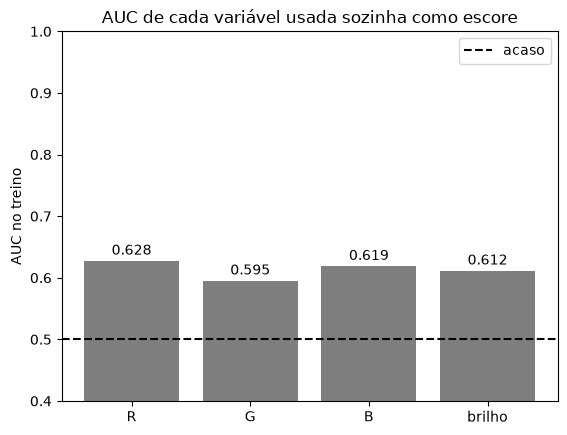

In [26]:
aucs = {}
for variavel in ["R", "G", "B", "brilho"]:
    aucs[variavel] = roc_auc_score(treino.rotulo, cores[variavel])

plt.bar(aucs.keys(), aucs.values(), color="tab:gray")
plt.axhline(0.5, color="black", linestyle="--", label="acaso")
for posicao, valor in enumerate(aucs.values()):
    plt.text(posicao, valor + 0.01, f"{valor:.3f}", ha="center")
plt.ylim(0.4, 1)
plt.title("AUC de cada variável usada sozinha como escore")
plt.ylabel("AUC no treino")
plt.legend()
plt.show()

**Análise:** a hipótese não se confirma. Usada sozinha, a melhor variável (média do canal R) chega a AUC 0,628, e as outras ficam entre 0,595 e 0,619, pouco acima do acaso (0,5). A diferença de cor entre as classes vista na EDA existe, mas não basta para separá-las. Esse valor serve de referência mínima: a CNN só agrega algo se ficar bem acima de 0,63.

## 5. Pré-processamento e métricas

#### Pipeline de dados
- **Tamanho:** cada recorte de 128 × 128 é ampliado para 224 × 224 (interpolação bilinear), o tamanho usado no treino da DenseNet121 no ImageNet. Os 3 canais RGB são mantidos.
- **Brilho:** as imagens são muito escuras, então multiplicamos os pixels por 2 e cortamos em 255. Com o fator 3 usado na visualização, 16% das imagens `com_garimpo` teriam mais de 5% dos pixels saturados, justo no solo claro. Com 2, são 4%.
- **`preprocess_input` da DenseNet:** divide por 255 e normaliza cada canal com a média e o desvio do ImageNet. Por isso não dividimos antes.
- **Aumento de dados, só no treino:** espelhamentos e rotações de 90°. Vista de cima, a paisagem não tem um lado certo. Como essas operações só mudam os pixels de lugar, tanto faz aplicá-las antes ou depois do `preprocess_input`.
- **Memória:** embaralhamos a lista de arquivos, antes de ler as imagens, e não usamos `.cache()`. As 14.000 imagens de treino já preparadas ocupariam cerca de 8 GB.
- **Imagens mascaradas:** continuam na amostra. O Grad-CAM vai mostrar se o modelo se apoia nas manchas pretas (H4).
- **Sementes:** a função `tabelas_da_semente` monta as tabelas de treino, validação e teste de qualquer semente. Abaixo mostramos a semente 42.

In [27]:
def tabelas_da_semente(semente):
    amostra_semente = divisoes[semente]
    tabelas = []
    for divisao in DIVISOES:
        tabela_divisao = amostra_semente[amostra_semente.divisao == divisao].reset_index(drop=True)
        tabela_divisao["caminho"] = str(PASTA_IMAGENS) + "/" + tabela_divisao.arquivo
        if MODO_RAPIDO:
            tabela_divisao = tabela_divisao.sample(200, random_state=semente).reset_index(drop=True)
        tabelas.append(tabela_divisao)
    return tabelas

treino, validacao, teste = tabelas_da_semente(SEMENTE)

exemplos_tabelas = pd.concat([treino.sample(4, random_state=SEMENTE),
                              validacao.sample(4, random_state=SEMENTE),
                              teste.sample(4, random_state=SEMENTE)])
exemplos_tabelas[["divisao", "caminho", "rotulo", "classe"]]

,divisao,caminho,rotulo,classe
2900,treino,dados/kaggle/dataset_amazonia_garimpo_binario/...,0,sem_garimpo
3143,treino,dados/kaggle/dataset_amazonia_garimpo_binario/...,0,sem_garimpo
8231,treino,dados/kaggle/dataset_amazonia_garimpo_binario/...,1,com_garimpo
3855,treino,dados/kaggle/dataset_amazonia_garimpo_binario/...,0,sem_garimpo
1801,validacao,dados/kaggle/dataset_amazonia_garimpo_binario/...,1,com_garimpo
1190,validacao,dados/kaggle/dataset_amazonia_garimpo_binario/...,0,sem_garimpo
1817,validacao,dados/kaggle/dataset_amazonia_garimpo_binario/...,1,com_garimpo
251,validacao,dados/kaggle/dataset_amazonia_garimpo_binario/...,0,sem_garimpo
1801,teste,dados/kaggle/dataset_amazonia_garimpo_binario/...,1,com_garimpo
1190,teste,dados/kaggle/dataset_amazonia_garimpo_binario/...,0,sem_garimpo


In [28]:
GANHO_BRILHO = 2

def carregar_e_preparar(caminho, rotulo):
    conteudo = tf.io.read_file(caminho)
    imagem = tf.io.decode_png(conteudo, channels=3)
    imagem = tf.image.resize(imagem, TAMANHO)
    imagem = tf.minimum(imagem * GANHO_BRILHO, 255)
    imagem = keras.applications.densenet.preprocess_input(imagem)
    return imagem, tf.cast(rotulo, tf.float32)

def aumentar(imagem, rotulo):
    imagem = tf.image.random_flip_left_right(imagem)
    imagem = tf.image.random_flip_up_down(imagem)
    voltas = tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32)
    imagem = tf.image.rot90(imagem, voltas)
    return imagem, rotulo

def criar_dataset(tabela, embaralhar=False, aumentar_dados=False):
    ds = tf.data.Dataset.from_tensor_slices((tabela.caminho.to_numpy(), tabela.rotulo.to_numpy()))
    if embaralhar:
        ds = ds.shuffle(len(tabela), seed=SEMENTE)
    ds = ds.map(carregar_e_preparar, num_parallel_calls=tf.data.AUTOTUNE)
    if aumentar_dados:
        ds = ds.map(aumentar, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [29]:
ds_treino = criar_dataset(treino, embaralhar=True, aumentar_dados=True)
ds_validacao = criar_dataset(validacao)
ds_teste = criar_dataset(teste)

resumo = []
for nome, ds, tabela in [("treino", ds_treino, treino), ("validacao", ds_validacao, validacao), ("teste", ds_teste, teste)]:
    imagens, rotulos = next(iter(ds))
    resumo.append({"dataset": nome,
                   "sem_garimpo": (tabela.rotulo == 0).sum(),
                   "com_garimpo": (tabela.rotulo == 1).sum(),
                   "lotes": len(ds),
                   "formato do lote": tuple(imagens.shape),
                   "formato dos rótulos": tuple(rotulos.shape)})
pd.DataFrame(resumo)

,dataset,sem_garimpo,com_garimpo,lotes,formato do lote,formato dos rótulos
0,treino,7031,6969,438,"(32, 224, 224, 3)","(32,)"
1,validacao,1507,1493,94,"(32, 224, 224, 3)","(32,)"
2,teste,1507,1493,94,"(32, 224, 224, 3)","(32,)"


#### Métricas e regra de seleção
- **Erro mais grave:** o falso negativo, um garimpo que passa sem ser detectado. Um falso positivo custa só uma verificação a mais.
- **Métrica principal: PR-AUC de `com_garimpo`.** Mede quanta precisão o modelo mantém à medida que o recall sobe, considerando todos os limiares. Ela escolhe a época (early stopping) e compara as condições.
- **Por que não o recall ou o F2:** com o limiar fixo, o recall do nosso primeiro treino da base congelada oscilou de 0,62 a 0,79 entre épocas, com a perda quase parada. Ele mostra para que lado o modelo pende no limiar, não se o modelo melhorou. O F2 depende do limiar do mesmo jeito e, com classes balanceadas, quase não separa um bom modelo de um que marca tudo como garimpo (F2 de 0,83).
- **Limiar:** 0,5 na probabilidade (logit ≥ 0), igual nas três condições e sem ajuste na validação. Nele calculamos acurácia, precisão, recall, F1 e a matriz de confusão.
- **Sementes:** cada condição é treinada nas 5 divisões. Comparamos a PR-AUC média ± desvio-padrão na validação. Uma diferença menor que o desvio conta como empate, e vence a condição mais barata.
- **Teste:** só é usado depois que o modelo recomendado estiver escolhido.

## 6. Transfer learning com base congelada

#### Base pré-treinada e novo classificador
Carregamos a DenseNet121 do Keras (`keras.applications`, TensorFlow/Keras) com os pesos do ImageNet e sem o classificador original (`include_top=False`). A base fica congelada: só a nova camada de saída aprende.

O pooling global transforma os 1024 mapas de 7 × 7 em um vetor de 1024 médias, e uma camada densa com um neurônio produz o logit. Logit positivo favorece `com_garimpo`, e a sigmoide o converte em probabilidade.

Como treinamos uma base por semente, a montagem fica na função `criar_modelo_base`.

In [30]:
def criar_modelo_base():
    base = keras.applications.DenseNet121(input_shape=(*TAMANHO, 3), include_top=False, weights="imagenet")
    base.trainable = False

    camada_gap = keras.layers.GlobalAveragePooling2D(name="media_global")
    camada_saida = keras.layers.Dense(1, name="logit")
    vetor_caracteristicas = camada_gap(base.output)
    logit = camada_saida(vetor_caracteristicas)

    return keras.Model(base.input, logit, name="base_congelada")

modelo_base = criar_modelo_base()
modelo_base.summary(layer_range=["bn", "logit"])

Model: "base_congelada"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ bn                  │ (None, 7, 7,      │      4,096 │ conv5_block16_co… │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu (Activation)   │ (None, 7, 7,      │          0 │ bn[0][0]          │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ media_global        │ (None, 1024)      │          0 │ relu[0][0]        │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logit (Dense)       │ (None, 1)         │      1,025 │ media_global[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

#### Configuração do treino

| Item | Valor |
| --- | --- |
| Entrada | 224 × 224 × 3 |
| Saída | 1 logit (`com_garimpo`) |
| Parâmetros | 7.038.529 no total, 1.025 treináveis (1024 pesos e 1 viés) |
| Otimizador | Adam, learning rate 1e-3 |
| Perda | entropia cruzada binária sobre o logit |
| Batch size | 32 |
| Épocas | até 30, com early stopping em `val_pr_auc` (paciência 5) e volta aos melhores pesos |
| Métricas no treino | acurácia, precisão, recall e PR-AUC de `com_garimpo` |
| Sementes | 42 a 46, uma base por semente |

As funções `compilar` e `treinar` serão usadas nas três condições, para que todas sigam essa mesma configuração. `treinar` também mede o tempo e salva o histórico em `resultados/`.

In [31]:
# No modo rápido, os arquivos vão para outra pasta e não se misturam com os do treino completo
PASTA_SAIDA = Path("rapido") if MODO_RAPIDO else Path(".")
PASTA_MODELOS = PASTA_SAIDA / "modelos"
PASTA_RESULTADOS = PASTA_SAIDA / "resultados"
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

def compilar(modelo, learning_rate):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                   loss=keras.losses.BinaryCrossentropy(from_logits=True),
                   metrics=[keras.metrics.BinaryAccuracy(name="acuracia", threshold=0.0),
                            keras.metrics.Precision(name="precisao", thresholds=0.0),
                            keras.metrics.Recall(name="recall", thresholds=0.0),
                            keras.metrics.AUC(name="pr_auc", curve="PR", from_logits=True)])

def treinar(modelo, nome, ds_treino, ds_validacao):
    parada_antecipada = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=PACIENCIA,
                                                      restore_best_weights=True)
    epocas = 1 if MODO_RAPIDO else EPOCAS

    inicio = time.perf_counter()
    historico = modelo.fit(ds_treino, validation_data=ds_validacao, epochs=epocas,
                           callbacks=[parada_antecipada], shuffle=False, verbose=2)
    duracao = time.perf_counter() - inicio

    registro = {}
    for metrica, valores in historico.history.items():
        registro[metrica] = [float(valor) for valor in valores]
    registro["epocas_executadas"] = len(registro["loss"])
    registro["tempo_segundos"] = round(duracao, 1)
    with open(PASTA_RESULTADOS / f"historico_{nome}.json", "w") as arquivo:
        json.dump(registro, arquivo, indent=2)

    print(f"{nome}: {registro['epocas_executadas']} épocas em {duracao / 60:.1f} min")
    return registro

#### Treino nas cinco sementes
Para cada semente, fixamos a semente aleatória, montamos os dados daquela divisão e treinamos uma base nova. Cada modelo salvo é a condição de referência da sua semente e o ponto de partida de A e B nela. Sementes já treinadas são puladas, para que uma interrupção não obrigue a refazer tudo.

In [32]:
historicos_base = {}
for semente in SEMENTES:
    nome = f"base_congelada_s{semente}"
    caminho_modelo = PASTA_MODELOS / f"{nome}.keras"
    if caminho_modelo.exists():
        with open(PASTA_RESULTADOS / f"historico_{nome}.json") as arquivo:
            historicos_base[semente] = json.load(arquivo)
        print(f"{nome}: já treinado, histórico carregado")
        continue

    keras.backend.clear_session()
    keras.utils.set_random_seed(semente)
    treino_semente, validacao_semente, teste_semente = tabelas_da_semente(semente)
    ds_treino_semente = criar_dataset(treino_semente, embaralhar=True, aumentar_dados=True)
    ds_validacao_semente = criar_dataset(validacao_semente)

    modelo = criar_modelo_base()
    compilar(modelo, learning_rate=1e-3)
    historicos_base[semente] = treinar(modelo, nome, ds_treino_semente, ds_validacao_semente)
    modelo.save(caminho_modelo)

Epoch 1/30
438/438 - 86s - 196ms/step - acuracia: 0.6784 - loss: 0.5770 - pr_auc: 0.7769 - precisao: 0.7363 - recall: 0.5516 - val_acuracia: 0.6977 - val_loss: 0.5500 - val_pr_auc: 0.8246 - val_precisao: 0.6694 - val_recall: 0.7756
Epoch 2/30
438/438 - 23s - 53ms/step - acuracia: 0.7141 - loss: 0.5367 - pr_auc: 0.8149 - precisao: 0.7578 - recall: 0.6258 - val_acuracia: 0.7227 - val_loss: 0.5219 - val_pr_auc: 0.8298 - val_precisao: 0.7852 - val_recall: 0.6095
Epoch 3/30
438/438 - 24s - 54ms/step - acuracia: 0.7161 - loss: 0.5305 - pr_auc: 0.8176 - precisao: 0.7533 - recall: 0.6391 - val_acuracia: 0.7257 - val_loss: 0.5221 - val_pr_auc: 0.8313 - val_precisao: 0.7939 - val_recall: 0.6062
Epoch 4/30
438/438 - 24s - 54ms/step - acuracia: 0.7238 - loss: 0.5239 - pr_auc: 0.8233 - precisao: 0.7596 - recall: 0.6512 - val_acuracia: 0.7243 - val_loss: 0.5203 - val_pr_auc: 0.8348 - val_precisao: 0.8159 - val_recall: 0.5760
Epoch 5/30
438/438 - 24s - 55ms/step - acuracia: 0.7241 - loss: 0.5202 - pr

#### Curvas de aprendizagem

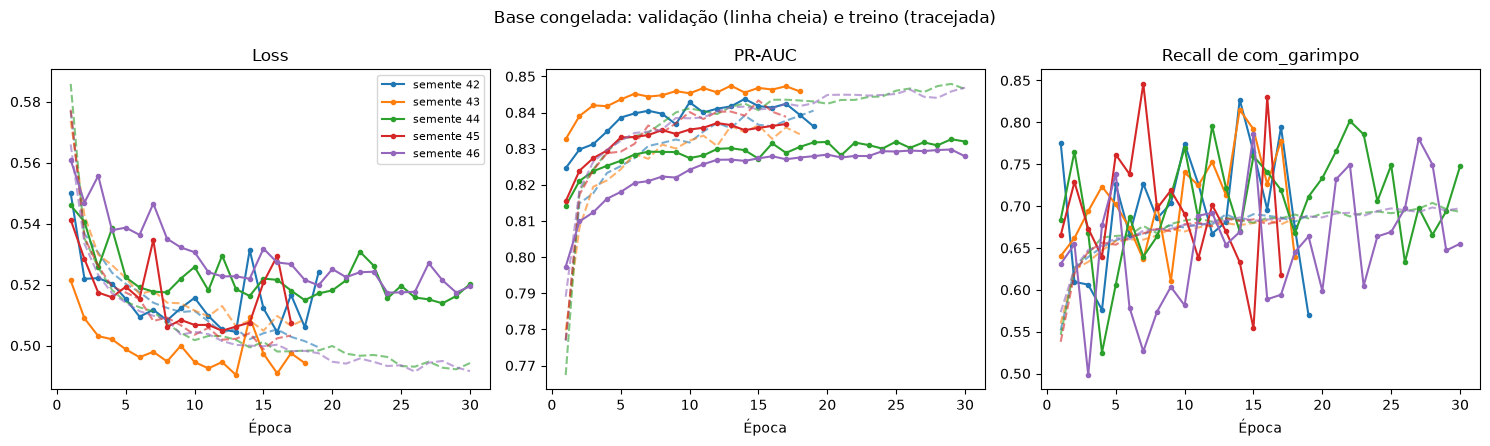

In [33]:
def plotar_curvas(historicos, titulo):
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
    for eixo, metrica, nome in zip(eixos, ["loss", "pr_auc", "recall"], ["Loss", "PR-AUC", "Recall de com_garimpo"]):
        numero = 0
        for semente, registro in historicos.items():
            cor = f"C{numero}"
            epocas = np.arange(1, len(registro[metrica]) + 1)
            eixo.plot(epocas, registro["val_" + metrica], color=cor, marker="o", markersize=3, label=f"semente {semente}")
            eixo.plot(epocas, registro[metrica], color=cor, linestyle="--", alpha=0.6)
            numero += 1
        eixo.set(xlabel="Época", title=nome)
    eixos[0].legend(fontsize=8)
    fig.suptitle(f"{titulo}: validação (linha cheia) e treino (tracejada)")
    plt.tight_layout()
    plt.show()

plotar_curvas(historicos_base, "Base congelada")

**Análise:** Nas cinco sementes, treino e validação andam juntos, sem sinal de overfitting. A PR-AUC de validação sobe rápido nas 5 primeiras épocas e depois quase não muda. As sementes 44 e 46 foram até a época 30 porque ainda ganhavam milésimos, menos de 0,005 depois da época 15. Já o recall de validação oscila entre 0,50 e 0,85 de uma época para outra, enquanto o de treino fica estável perto de 0,69. Com a perda quase parada, um pequeno deslocamento nos scores basta para muitas imagens cruzarem o limiar de 0,5. Por isso a parada usa a PR-AUC, e não o recall. O nível das curvas também muda com a semente (a 43 fica acima das outras desde a primeira época), o que mostra o peso da divisão nos resultados.

#### Avaliação na validação
Cada modelo é recarregado do seu arquivo `.keras` e avaliado na validação da sua semente. A tabela traz a PR-AUC e, no limiar de 0,5, acurácia, precisão, recall e F1 de `com_garimpo`, além das épocas e do tempo de treino, com média e desvio-padrão nas sementes.

In [34]:
def prever(modelo, ds):
    logits = modelo.predict(ds, verbose=0).reshape(-1)
    return tf.sigmoid(logits).numpy()

def metricas_validacao(rotulos, probabilidades):
    previstos = (probabilidades >= 0.5).astype(int)
    return {"PR-AUC": average_precision_score(rotulos, probabilidades),
            "acurácia": accuracy_score(rotulos, previstos),
            "precisão": precision_score(rotulos, previstos, zero_division=0),
            "recall": recall_score(rotulos, previstos),
            "F1": f1_score(rotulos, previstos)}

def avaliar_sementes(condicao, historicos):
    linhas = {}
    probabilidades = {}
    for semente in SEMENTES:
        modelo = keras.models.load_model(PASTA_MODELOS / f"{condicao}_s{semente}.keras")
        treino_semente, validacao_semente, teste_semente = tabelas_da_semente(semente)
        probabilidades[semente] = prever(modelo, criar_dataset(validacao_semente))
        linha = metricas_validacao(validacao_semente.rotulo, probabilidades[semente])
        linha["épocas"] = historicos[semente]["epocas_executadas"]
        linha["tempo (min)"] = historicos[semente]["tempo_segundos"] / 60
        linhas[semente] = linha
    resultados = pd.DataFrame(linhas).T
    resultados.loc["média"] = resultados.loc[SEMENTES].mean()
    resultados.loc["desvio-padrão"] = resultados.loc[SEMENTES].std()
    return resultados, probabilidades

resultados_base, probabilidades_base = avaliar_sementes("base_congelada", historicos_base)
resultados_base.round(3)

,PR-AUC,acurácia,precisão,recall,F1,épocas,tempo (min)
42,0.844,0.714,0.673,0.827,0.742,19.000,8.778
43,0.848,0.750,0.768,0.713,0.740,18.000,8.140
44,0.832,0.742,0.766,0.694,0.728,30.000,13.150
45,0.837,0.743,0.764,0.701,0.731,17.000,7.682
46,0.830,0.731,0.775,0.647,0.705,30.000,13.260
média,0.838,0.736,0.749,0.717,0.729,22.800,10.202
desvio-padrão,0.008,0.014,0.043,0.067,0.015,6.611,2.769


**Análise:** A PR-AUC varia pouco entre as sementes: 0,838 ± 0,008, de 0,830 (semente 46) a 0,848 (semente 43). F1 e acurácia também são estáveis (0,729 ± 0,015 e 0,736 ± 0,014). Já precisão e recall no limiar de 0,5 variam bem mais: o recall vai de 0,647 a 0,827 (desvio de 0,067). Como o F1 quase não muda, nenhuma semente ficou melhor ou pior; elas só trocam falsos negativos por falsos positivos, conforme o ponto em que o limiar caiu na época escolhida. A PR-AUC de 0,838 ± 0,008 é a referência para A e B, e diferenças menores que o desvio contam como empate. Cada base levou em média 10,2 minutos.

#### Semente 42 em detalhe
Relatório por classe e matriz de confusão da base da semente 42, a usada na análise visual preliminar. A AUC ROC entra para comparar com a linha de base da cor média (H5, AUC 0,63). As probabilidades ficam na tabela `previsoes_validacao`, uma coluna por condição.

              precision    recall  f1-score   support

 sem_garimpo      0.779     0.602     0.679      1507
 com_garimpo      0.673     0.827     0.742      1493

    accuracy                          0.714      3000
   macro avg      0.726     0.715     0.711      3000
weighted avg      0.726     0.714     0.710      3000

PR-AUC: 0.844
AUC ROC: 0.827


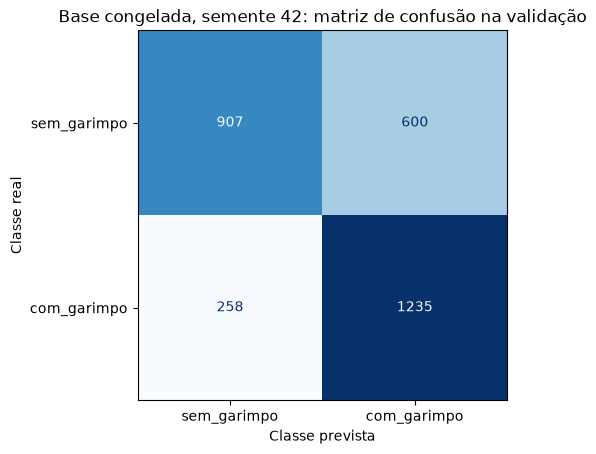

,arquivo,rotulo,classe,base_congelada
0,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,0,sem_garimpo,0.696652
1,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,0,sem_garimpo,0.057267
2,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,0,sem_garimpo,0.374465
3,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,0,sem_garimpo,0.336298
4,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,0,sem_garimpo,0.944129


In [35]:
def mostrar_desempenho(rotulos, probabilidades, titulo):
    previstos = (probabilidades >= 0.5).astype(int)
    print(classification_report(rotulos, previstos, labels=[0, 1], target_names=NOMES_CLASSES, digits=3, zero_division=0))
    print(f"PR-AUC: {average_precision_score(rotulos, probabilidades):.3f}")
    print(f"AUC ROC: {roc_auc_score(rotulos, probabilidades):.3f}")
    ConfusionMatrixDisplay.from_predictions(rotulos, previstos, labels=[0, 1], display_labels=NOMES_CLASSES,
                                            cmap="Blues", colorbar=False)
    plt.title(f"{titulo}: matriz de confusão na validação")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.show()

previsoes_validacao = validacao[["arquivo", "rotulo", "classe"]].copy()
previsoes_validacao["base_congelada"] = probabilidades_base[SEMENTE]
mostrar_desempenho(previsoes_validacao.rotulo, previsoes_validacao.base_congelada, f"Base congelada, semente {SEMENTE}")
previsoes_validacao.head()

**Análise:** A semente 42 é a que mais puxa para `com_garimpo`. Ela acerta 71,4% da validação, com recall de 0,827 em `com_garimpo` e só 0,602 em `sem_garimpo`: 600 falsos positivos contra 258 falsos negativos. Nas outras sementes o recall fica entre 0,647 e 0,713, com a mesma PR-AUC. A melhor PR-AUC dela caiu na época 14, um pico do recall nas curvas acima, então o recall alto vem do ponto do limiar, não de um modelo melhor. A AUC ROC de 0,827 segue bem acima dos 0,63 da cor média (H5): a rede usa mais do que a cor.

## 7. Análise visual preliminar
Erros e acertos da base congelada da semente 42 na validação. O score é a probabilidade que o modelo atribui à classe prevista. As imagens aparecem com brilho ×3, como na EDA, só para facilitar a visualização.

In [36]:
casos = validacao[["arquivo", "classe", "overlap_ratio"]].copy()
casos["probabilidade_com"] = previsoes_validacao.base_congelada
casos["prevista"] = np.where(casos.probabilidade_com >= 0.5, "com_garimpo", "sem_garimpo")
casos["score"] = np.where(casos.prevista == "com_garimpo", casos.probabilidade_com, 1 - casos.probabilidade_com)

casos["tipo"] = "acerto"
casos.loc[(casos.classe == "com_garimpo") & (casos.prevista == "sem_garimpo"), "tipo"] = "falso negativo"
casos.loc[(casos.classe == "sem_garimpo") & (casos.prevista == "com_garimpo"), "tipo"] = "falso positivo"

casos.groupby(["classe", "prevista"]).score.agg(imagens="count", score_medio="mean", score_mediano="median").round(3)

imagens  score_medio  score_mediano
classe      prevista                                        
com_garimpo com_garimpo     1235        0.823          0.861
            sem_garimpo      258        0.616          0.585
sem_garimpo com_garimpo      600        0.656          0.626
            sem_garimpo      907        0.691          0.681

In [37]:
def mostrar_casos(tabela, titulo, quantidade=8):
    selecionados = tabela.head(quantidade)
    if len(selecionados) == 0:
        print(f"{titulo}: nenhum exemplo encontrado.")
        return

    linhas = (len(selecionados) + 3) // 4
    fig, eixos = plt.subplots(linhas, 4, figsize=(13, 4.6 * linhas), squeeze=False)
    for eixo in eixos.ravel():
        eixo.axis("off")

    for eixo, caso in zip(eixos.ravel(), selecionados.itertuples()):
        imagem = ler_imagem(caso.arquivo).astype("float32") * AUMENTO_BRILHO
        eixo.imshow(np.clip(imagem, 0, 255).astype("uint8"))
        eixo.set_title(f"Real: {caso.classe}\nPrevista: {caso.prevista}\n"
                       f"Score: {caso.score:.1%} | overlap {caso.overlap_ratio:.2f}", fontsize=9)

    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

#### Erros de maior score
Os erros em que o modelo estava mais confiante. Não representam todos os erros, só os mais extremos.

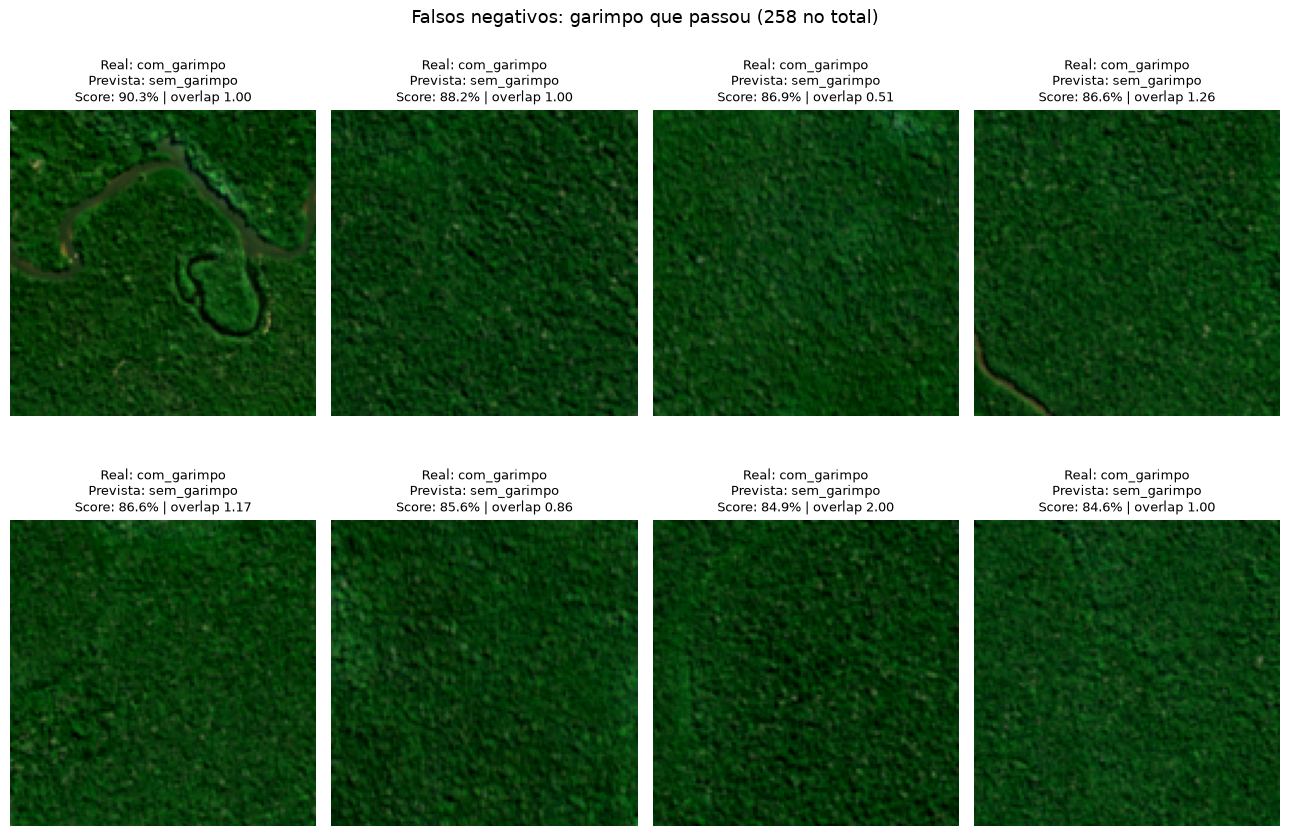

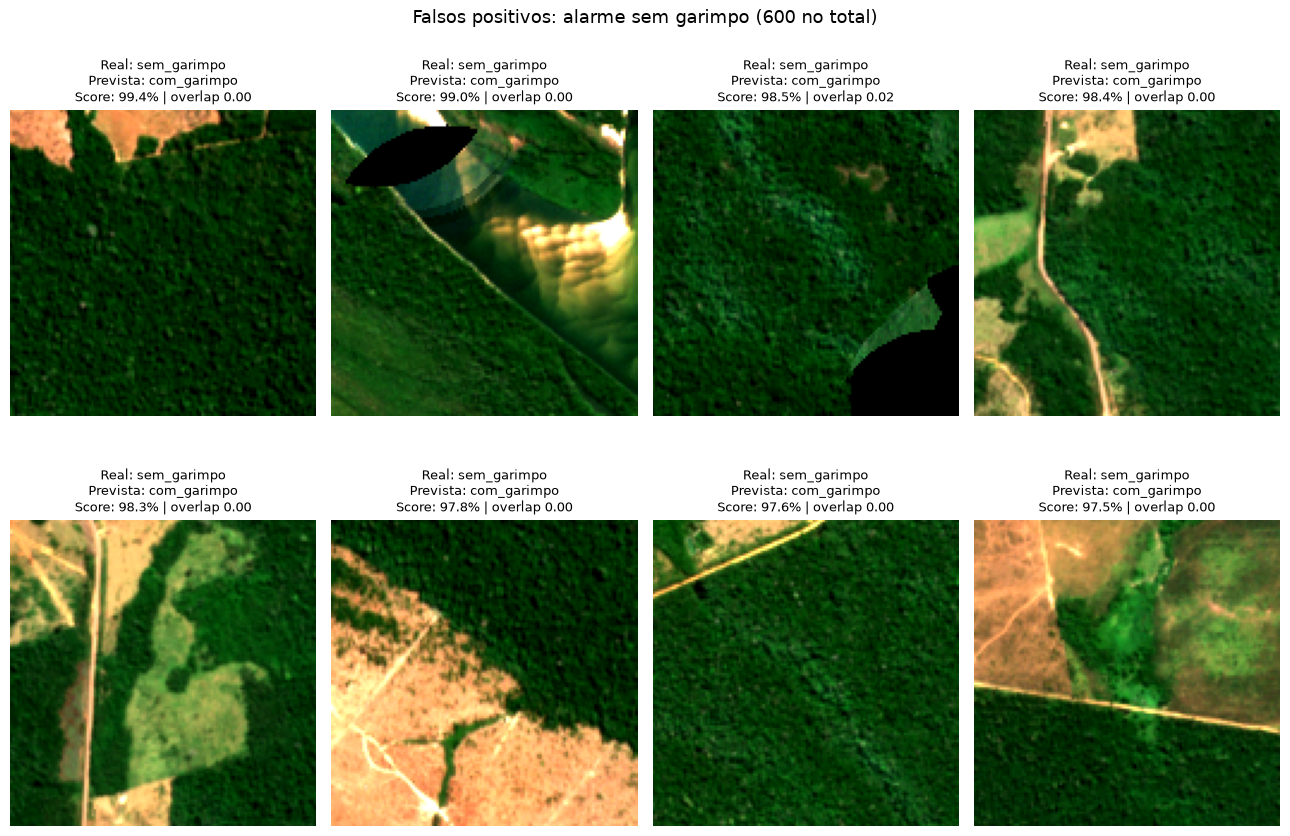

In [38]:
falsos_negativos = casos[casos.tipo == "falso negativo"].sort_values("score", ascending=False)
falsos_positivos = casos[casos.tipo == "falso positivo"].sort_values("score", ascending=False)

mostrar_casos(falsos_negativos, f"Falsos negativos: garimpo que passou ({len(falsos_negativos)} no total)")
mostrar_casos(falsos_positivos, f"Falsos positivos: alarme sem garimpo ({len(falsos_positivos)} no total)")

#### Acertos das duas classes
Amostra aleatória dos acertos, para comparar com os erros.

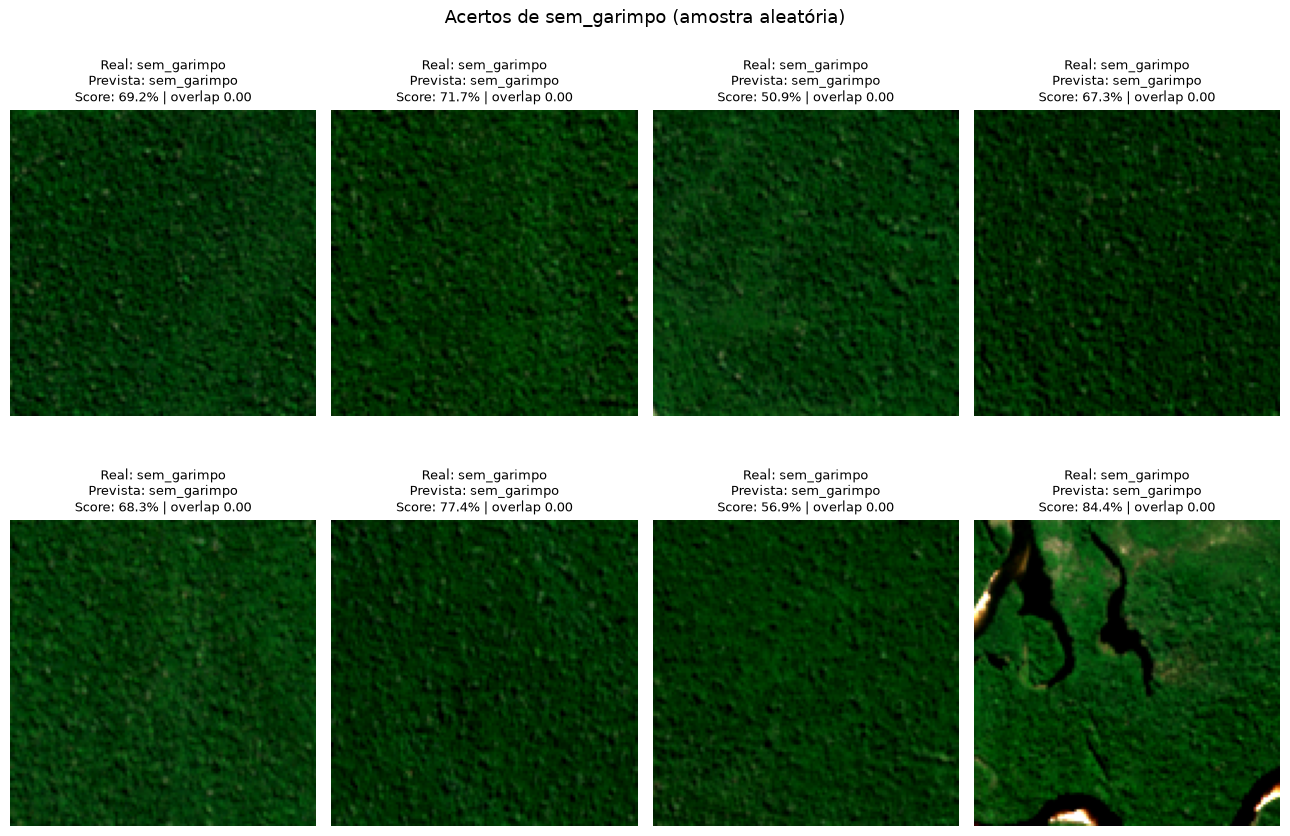

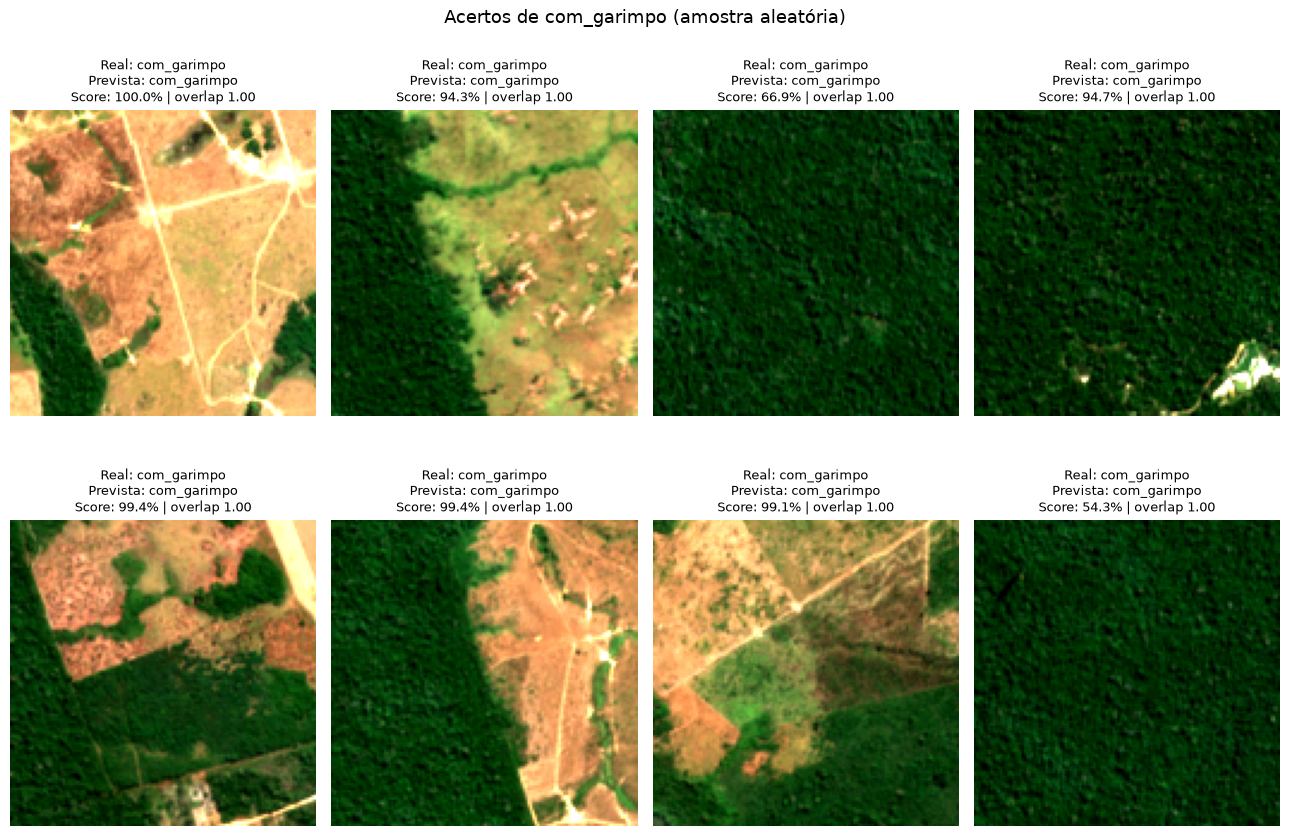

In [39]:
for classe in NOMES_CLASSES:
    acertos = casos[(casos.tipo == "acerto") & (casos.classe == classe)]
    mostrar_casos(acertos.sample(8, random_state=SEMENTE), f"Acertos de {classe} (amostra aleatória)")

**Análise:** Quando erra, o modelo costuma estar em dúvida: o score médio é 0,62 nos falsos negativos e 0,66 nos falsos positivos, contra 0,82 nos acertos de `com_garimpo`. Os falsos negativos mais confiantes são floresta fechada com overlap de 0,5 ou mais. O polígono marca a área, mas o recorte não mostra garimpo, a limitação vista na H1. Os falsos positivos mais confiantes, com score acima de 97%, têm pasto, solo exposto, estradas e áreas mascaradas: o modelo trata qualquer abertura na floresta, e as manchas pretas, como garimpo. Nos acertos, as imagens de `com_garimpo` com solo exposto chegam perto de 100%, mas os acertos de `sem_garimpo` ficam em média em 0,69: como há floresta fechada nas duas classes, o modelo nunca tem muita certeza dela. O fine-tuning pode ajudar a separar o garimpo de outros desmatamentos, mas não corrige rótulos sem marca visível. Esta análise será refeita na semente do modelo escolhido.

## 8. Fine-tuning A e B

Até aqui só o classificador `logit` foi treinado. Agora liberamos também pesos da DenseNet121, em duas profundidades, para ver se adaptar a rede às imagens de satélite compensa o custo.

| Estratégia | Camadas treináveis | Parâmetros treináveis | Parte do total |
| --- | --- | --- | --- |
| Base congelada (referência) | `logit` | 1.025 | 0,01% |
| **A** | `conv5_*` (bloco denso 4) e `logit` | 2.130.945 | 30,3% |
| **B** | `conv4_*`, `pool4_*` (bloco denso 3 e transição) e `conv5_*` (bloco denso 4) e `logit` | 5.456.897 | 77,5% |

- **O que muda:** só as camadas descongeladas. B libera as mesmas camadas de A e mais o bloco denso 3, com 2,6 vezes mais parâmetros treináveis.
- **O que fica fixo:** learning rate de 1e-5, Adam, batch de 32, até 30 épocas, early stopping em `val_pr_auc` com paciência 5, mesmos dados, mesmo aumento e mesmas cinco sementes. Em cada semente, A e B partem de cópias do arquivo `base_congelada_s<semente>.keras`, carregado do disco, nunca de um modelo que já esteja na memória.
- **Learning rate baixo:** 1e-5 é cem vezes menor que o da base congelada. Os pesos já aprenderam bordas e texturas no ImageNet, e passos grandes poderiam apagar isso logo nas primeiras épocas.
- **BatchNormalization congelada:** as camadas `BatchNormalization` ficam fixas nas duas estratégias. Elas guardam média e variância calculadas no ImageNet; se também fossem atualizadas com lotes de 32 imagens muito escuras, essas estatísticas poderiam se desajustar e a rede perderia parte do que já sabe.
- **Por que testar:** os erros da seção 7 mostram o modelo confundindo garimpo com pasto, estradas e solo exposto. Adaptar os blocos finais pode ajudar a separar o garimpo de outros desmatamentos, mas não corrige rótulos sem marca visível (H1). B testa se adaptar também o bloco 3 compensa o custo extra.
- **Como se decide:** pela PR-AUC média na validação. Começamos pela base, que é a mais barata, e só trocamos por uma condição mais cara se a média dela superar a da escolhida até ali por mais que o maior dos dois desvios-padrão. Diferença menor conta como empate e fica a mais barata.

#### Descongelamento

A função `descongelar` deixa treináveis as camadas cujo nome começa com os prefixos pedidos, mais o `logit`, e mantém toda `BatchNormalization` congelada. Como `trainable` mudou, o modelo precisa ser recompilado depois. A tabela confere a contagem de parâmetros treináveis de A numa cópia da base da semente 42; os valores esperados são 2.130.945 e nenhuma `BatchNormalization` treinável.

In [ ]:
def descongelar(modelo, prefixos):
    for camada in modelo.layers:
        camada.trainable = camada.name.startswith(prefixos) or camada.name == "logit"
        if isinstance(camada, keras.layers.BatchNormalization):
            camada.trainable = False

def resumir_treinaveis(modelo):
    parametros = sum(int(np.prod(peso.shape)) for peso in modelo.trainable_weights)
    total = modelo.count_params()
    normalizacoes = sum(1 for camada in modelo.layers
                        if isinstance(camada, keras.layers.BatchNormalization) and camada.trainable)
    return {"parâmetros treináveis": parametros, "% do total": round(100 * parametros / total, 1),
            "BatchNormalization treináveis": normalizacoes}

parametros_treinaveis = {}

modelo_exemplo = keras.models.load_model(PASTA_MODELOS / f"base_congelada_s{SEMENTE}.keras")
parametros_treinaveis["base_congelada"] = resumir_treinaveis(modelo_exemplo)["parâmetros treináveis"]

descongelar(modelo_exemplo, ("conv5_",))
parametros_treinaveis["fine_tuning_a"] = resumir_treinaveis(modelo_exemplo)["parâmetros treináveis"]
pd.DataFrame([resumir_treinaveis(modelo_exemplo)], index=["Fine-tuning A"])

#### Treino do fine-tuning A

Para cada semente, o laço carrega a base daquela semente do arquivo, libera `conv5_*` e treina com learning rate de 1e-5, com os mesmos dados da base. Sementes já treinadas são puladas.

In [ ]:
historicos_a = {}
for semente in SEMENTES:
    nome = f"fine_tuning_a_s{semente}"
    caminho_modelo = PASTA_MODELOS / f"{nome}.keras"
    if caminho_modelo.exists():
        with open(PASTA_RESULTADOS / f"historico_{nome}.json") as arquivo:
            historicos_a[semente] = json.load(arquivo)
        print(f"{nome}: já treinado, histórico carregado")
        continue

    keras.backend.clear_session()
    keras.utils.set_random_seed(semente)
    treino_semente, validacao_semente, teste_semente = tabelas_da_semente(semente)
    ds_treino_semente = criar_dataset(treino_semente, embaralhar=True, aumentar_dados=True)
    ds_validacao_semente = criar_dataset(validacao_semente)

    modelo = keras.models.load_model(PASTA_MODELOS / f"base_congelada_s{semente}.keras")
    descongelar(modelo, ("conv5_",))
    compilar(modelo, learning_rate=1e-5)
    historicos_a[semente] = treinar(modelo, nome, ds_treino_semente, ds_validacao_semente)
    modelo.save(caminho_modelo)

#### Curvas de aprendizagem do fine-tuning A

In [ ]:
plotar_curvas(historicos_a, "Fine-tuning A")

**Análise:** TODO(análise)

#### Avaliação do fine-tuning A na validação

Mesma avaliação da base: cada modelo é recarregado do seu `.keras` e avaliado na validação da sua semente. A segunda tabela compara a PR-AUC de A com a da base, semente a semente.

In [ ]:
resultados_a, probabilidades_a = avaliar_sementes("fine_tuning_a", historicos_a)
display(resultados_a.round(3))

comparacao_a = pd.DataFrame({"base": resultados_base["PR-AUC"], "A": resultados_a["PR-AUC"]})
comparacao_a["A - base"] = comparacao_a["A"] - comparacao_a["base"]
comparacao_a.round(3)

**Análise:** TODO(análise)

#### Treino do fine-tuning B

Mesmo laço de A, com a mesma configuração. A diferença é `descongelar(modelo, ("conv4_", "pool4_", "conv5_"))`, e cada modelo parte de outra cópia do mesmo arquivo da base. A tabela confere a contagem de B; os valores esperados são 5.456.897 e nenhuma `BatchNormalization` treinável.

In [ ]:
modelo_exemplo = keras.models.load_model(PASTA_MODELOS / f"base_congelada_s{SEMENTE}.keras")
descongelar(modelo_exemplo, ("conv4_", "pool4_", "conv5_"))
parametros_treinaveis["fine_tuning_b"] = resumir_treinaveis(modelo_exemplo)["parâmetros treináveis"]
pd.DataFrame([resumir_treinaveis(modelo_exemplo)], index=["Fine-tuning B"])

In [ ]:
historicos_b = {}
for semente in SEMENTES:
    nome = f"fine_tuning_b_s{semente}"
    caminho_modelo = PASTA_MODELOS / f"{nome}.keras"
    if caminho_modelo.exists():
        with open(PASTA_RESULTADOS / f"historico_{nome}.json") as arquivo:
            historicos_b[semente] = json.load(arquivo)
        print(f"{nome}: já treinado, histórico carregado")
        continue

    keras.backend.clear_session()
    keras.utils.set_random_seed(semente)
    treino_semente, validacao_semente, teste_semente = tabelas_da_semente(semente)
    ds_treino_semente = criar_dataset(treino_semente, embaralhar=True, aumentar_dados=True)
    ds_validacao_semente = criar_dataset(validacao_semente)

    modelo = keras.models.load_model(PASTA_MODELOS / f"base_congelada_s{semente}.keras")
    descongelar(modelo, ("conv4_", "pool4_", "conv5_"))
    compilar(modelo, learning_rate=1e-5)
    historicos_b[semente] = treinar(modelo, nome, ds_treino_semente, ds_validacao_semente)
    modelo.save(caminho_modelo)

#### Curvas de aprendizagem do fine-tuning B

In [ ]:
plotar_curvas(historicos_b, "Fine-tuning B")

**Análise:** TODO(análise)

#### Avaliação do fine-tuning B na validação

In [ ]:
resultados_b, probabilidades_b = avaliar_sementes("fine_tuning_b", historicos_b)
display(resultados_b.round(3))

comparacao_b = pd.DataFrame({"base": resultados_base["PR-AUC"], "A": resultados_a["PR-AUC"], "B": resultados_b["PR-AUC"]})
comparacao_b["B - A"] = comparacao_b["B"] - comparacao_b["A"]
comparacao_b["B - base"] = comparacao_b["B"] - comparacao_b["base"]
comparacao_b.round(3)

**Análise:** TODO(análise)